In [ ]:
import pandas as pd

# Loading data
df = pd.read_csv("weightLogInfo_merged.csv")
df_bmi_usage = pd.read_csv('usage_11_weight_login.csv')

# Cleaning data
df['Date'] = pd.to_datetime(df['Date'],
    format='%m/%d/%Y %I:%M:%S %p')

In [30]:
df_original = df.copy()
df = df.drop_duplicates()

print('Original:', len(df_original))
print('Cleaned:', len(df))
print('Rows dropped:', len(df_original) - len(df))

Original: 33
Cleaned: 33
Rows dropped: 0


In [31]:
df = df.rename(columns={'Id':'user_id',
                   'Date':'date',
                   'WeightKg':'weight_kg',
                   'WeightPounds':'weight_pounds',
                   'Fat':'fat',
                   'BMI':'bmi',
                   'IsManualReport':'is_manual_report',
                   'LogId':'log_id'
                    })

In [32]:
df.groupby('user_id')['is_manual_report'].nunique()


user_id
1503960366    1
1927972279    1
2347167796    1
2873212765    1
2891001357    1
4445114986    1
4558609924    1
4702921684    1
6962181067    1
8253242879    1
8877689391    1
Name: is_manual_report, dtype: int64

In [33]:
df['input_method'] = (df['is_manual_report'].map({True:'Manual',False:'Non-Manual'}))

df_manual_users = df[['user_id','input_method']].drop_duplicates().reset_index(drop=True)

df_manual_users

,user_id,input_method
0,1503960366,Manual
1,1927972279,Non-Manual
2,2347167796,Manual
3,2873212765,Manual
4,2891001357,Manual
5,4445114986,Manual
6,4558609924,Manual
7,4702921684,Manual
8,6962181067,Manual
9,8253242879,Manual


In [37]:
df_manual_users.columns

Index(['user_id', 'input_method'], dtype='object')

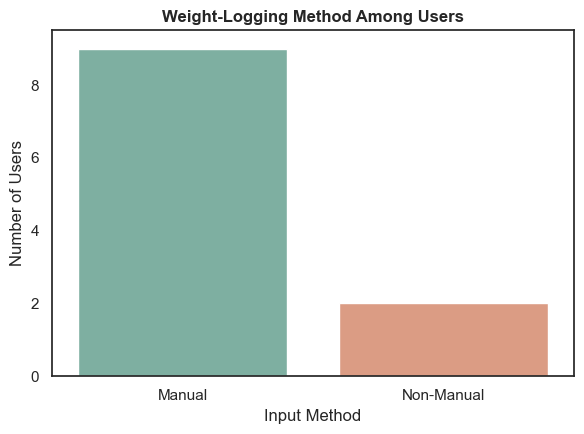

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the chart style
sns.set_theme(style='white')

# Set the figure size
plt.figure(figsize=(6, 4.5))

# Create the bar chart
ax = sns.countplot(
    data=df_manual_users,
    x='input_method',
    order=['Manual', 'Non-Manual'],
    hue='input_method',
    palette={
        'Manual': '#76B7A5',
        'Non-Manual': '#E99675'
    },
    legend=False
)

# Set the chart title and labels
plt.title(
    'Weight-Logging Method Among Users',
    fontweight='bold'
)

plt.xlabel('Input Method')
plt.ylabel('Number of Users')

# Set the Y-axis range
plt.ylim(0, 9.5)

plt.tight_layout()
plt.show()